# GNN Project


Dans quelle mesure la structure topologique du réseau aérien améliore-t-elle la prédiction du pays d’un aéroport par rapport à ses seules caractéristiques individuelles ?

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import seaborn as sns
import torch as th
import torch.nn.functional as F
from matplotlib.cm import ScalarMappable
from sklearn.manifold import TSNE
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder
from torch import nn
from torch_geometric.nn import VGAE, GCNConv
from torch_geometric.transforms import RandomLinkSplit
from torch_geometric.utils import from_networkx, to_networkx


/opt/anaconda3/lib/python3.14/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [4]:
# Load graph
G = nx.read_graphml("airportsAndCoordAndPop.graphml")

# Infos générales
print(G)
print(f"Attributs des nœuds : {list(G.nodes(data=True))[:1]}")

Graph with 3363 nodes and 13547 edges
Attributs des nœuds : [('0', {'lon': -145.50972222222222, 'lat': -17.35388888888889, 'population': 10000, 'country': 'FRENCH_POLYNESIA', 'city_name': 'Anaa'})]


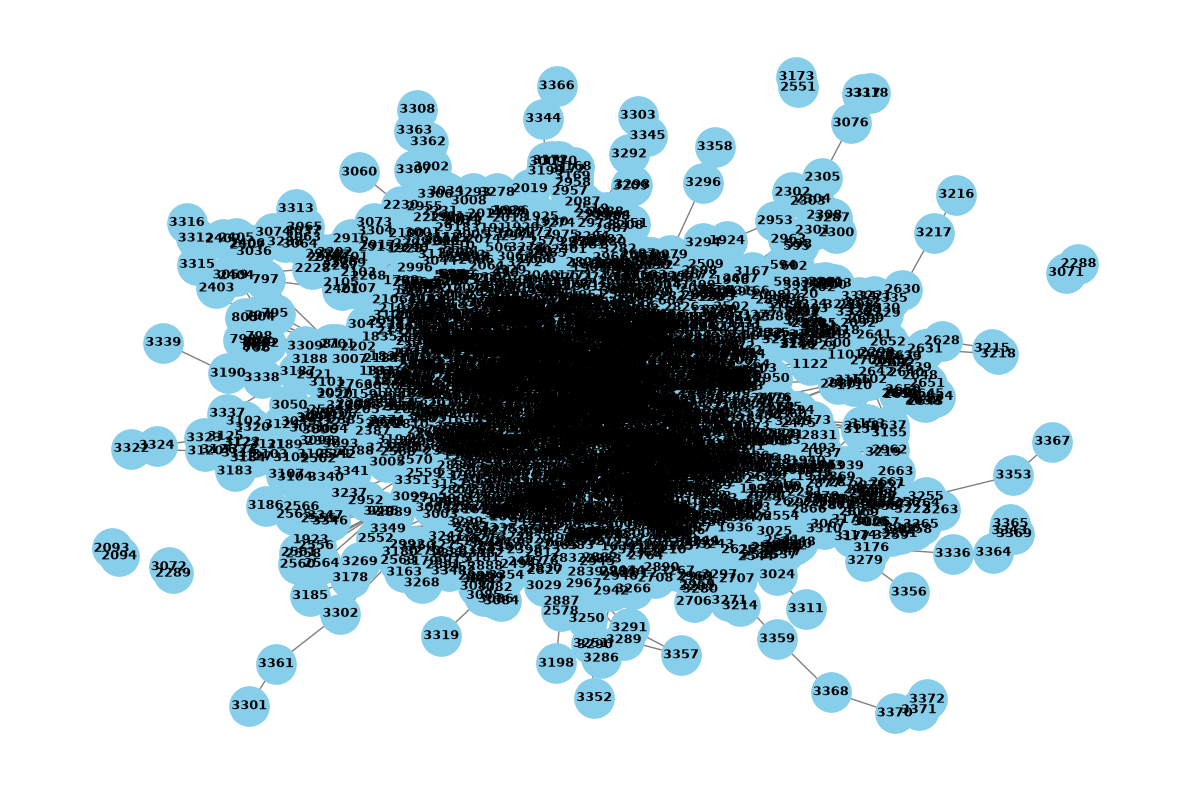

In [5]:
# First visualization

plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx(
    G,
    pos=pos,
    node_size=800,
    node_color="skyblue",
    edge_color="gray",
    font_size=9,
    font_weight="bold",
    arrows=True
)

plt.axis("off")
plt.tight_layout()
plt.show()

### Better visualization for a large graph

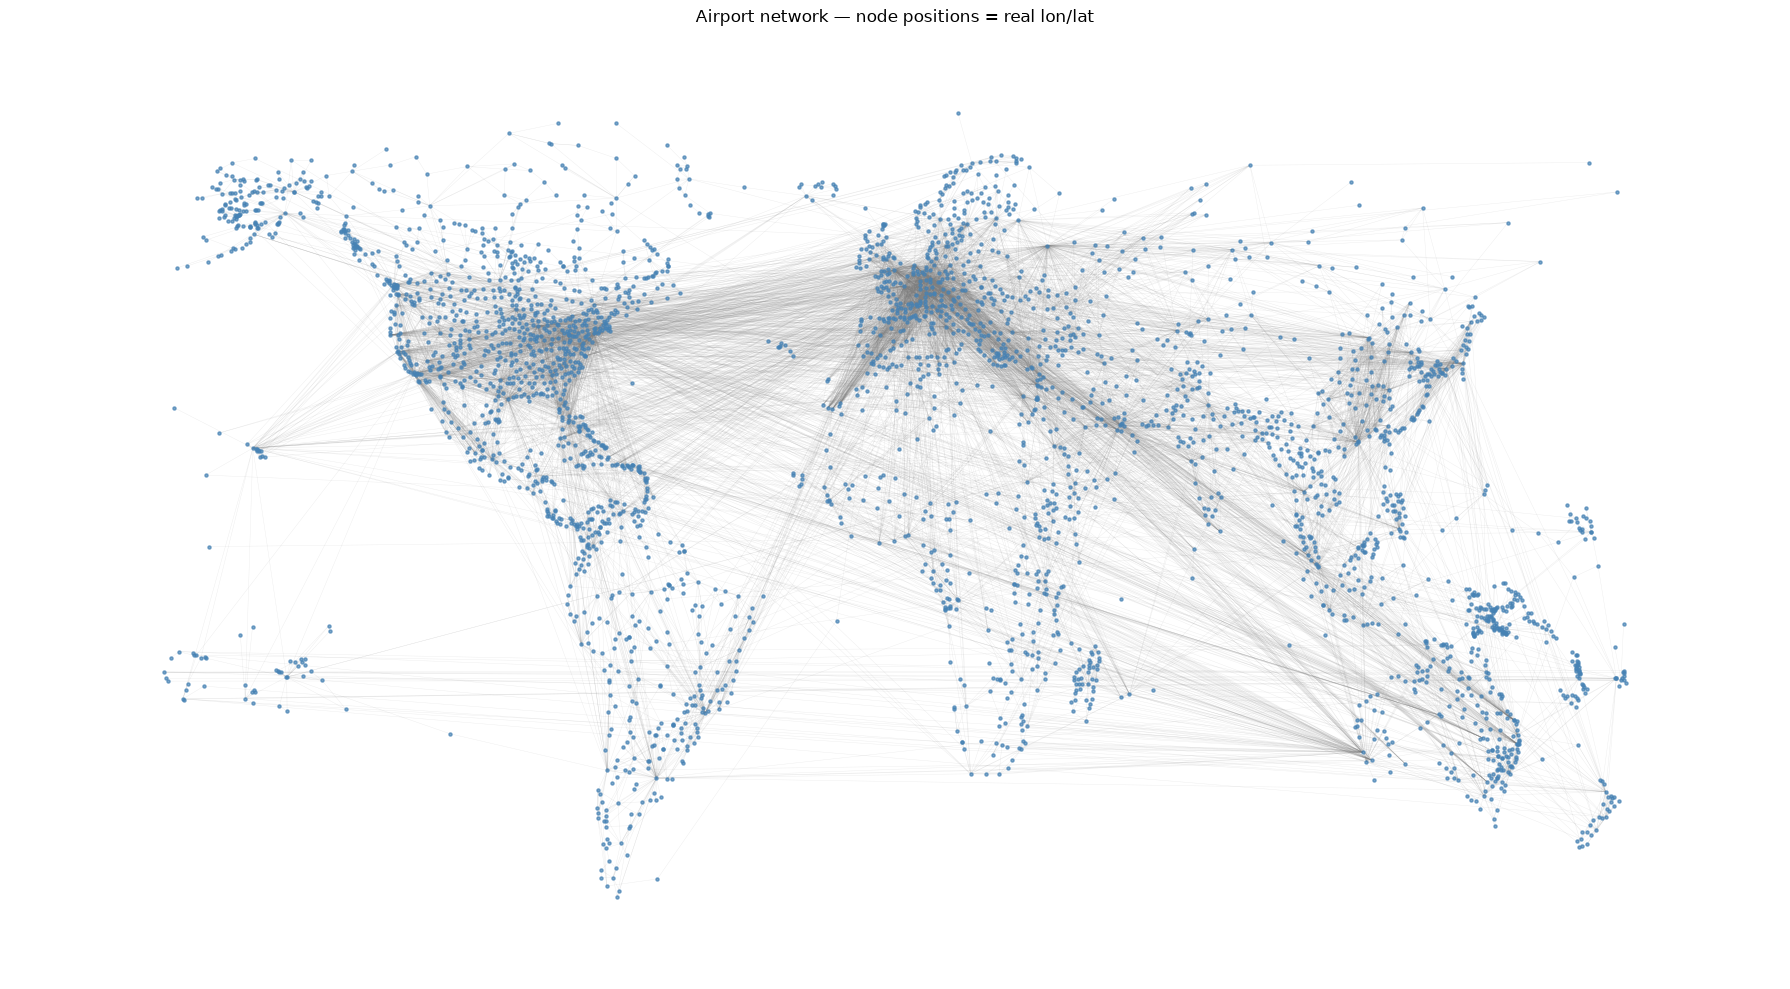

In [6]:
# Static visualization using real geographic coordinates as node positions

geo_pos = {n: (d["lon"], d["lat"]) for n, d in G.nodes(data=True)}

plt.figure(figsize=(18, 10))
nx.draw_networkx_edges(G, pos=geo_pos, width=0.3, alpha=0.15, edge_color="gray")
nx.draw_networkx_nodes(G, pos=geo_pos, node_size=5, node_color="steelblue", alpha=0.7)

plt.axis("off")
plt.title("Airport network — node positions = real lon/lat")
plt.tight_layout()
plt.show()

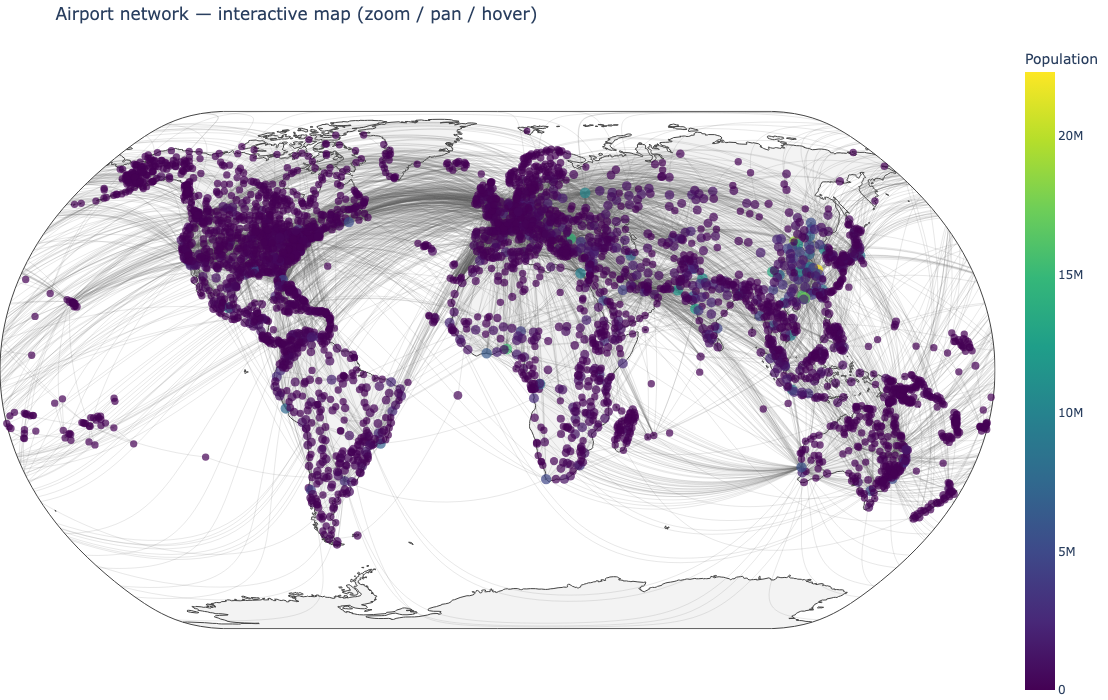

In [7]:
# Interactive visualization (zoom / pan / hover) with Plotly

import numpy as np
import plotly.graph_objects as go

# Edges as a single trace, segments separated by None to avoid one trace per edge
edge_lon, edge_lat = [], []
for u, v in G.edges():
    edge_lon += [G.nodes[u]["lon"], G.nodes[v]["lon"], None]
    edge_lat += [G.nodes[u]["lat"], G.nodes[v]["lat"], None]

edge_trace = go.Scattergeo(
    lon=edge_lon,
    lat=edge_lat,
    mode="lines",
    line=dict(width=0.5, color="rgba(100,100,100,0.3)"),
    hoverinfo="none",
    showlegend=False,
)

node_lon = [d["lon"] for _, d in G.nodes(data=True)]
node_lat = [d["lat"] for _, d in G.nodes(data=True)]
node_pop = np.array([d["population"] for _, d in G.nodes(data=True)], dtype=float)
node_text = [
    f"{d['city_name']} ({d['country']})<br>Population: {d['population']:,}"
    for _, d in G.nodes(data=True)
]
# Scale marker size with log(population) so both small and huge cities stay visible
node_size = 3 + 8 * (np.log1p(node_pop) / np.log1p(node_pop).max())

node_trace = go.Scattergeo(
    lon=node_lon,
    lat=node_lat,
    mode="markers",
    marker=dict(
        size=node_size,
        color=node_pop,
        colorscale="Viridis",
        cmin=0,
        colorbar=dict(title="Population"),
        line=dict(width=0),
    ),
    text=node_text,
    hoverinfo="text",
    showlegend=False,
)

fig = go.Figure(data=[edge_trace, node_trace])
fig.update_layout(
    title="Airport network — interactive map (zoom / pan / hover)",
    geo=dict(
        projection_type="natural earth",
        showland=True,
        landcolor="rgb(243, 243, 243)",
        countrycolor="rgb(204, 204, 204)",
    ),
    height=700,
    margin=dict(l=0, r=0, t=40, b=0),
)
fig.show()


We have noticed disparity. There are aiports that represent hub with high degrees. In other hand some of the aerport have very low degree. It exists countries with only one airport or in any case a very little number of airport, this introduce unbalanced class

## Classification task: predicting an airport's country

The target class is the `country` node attribute. Before building a classifier, let's look at how many classes (countries) there are and how balanced they are.

In [8]:
# Number of classes (countries) and number of airports per class

import pandas as pd

country_counts = pd.Series([d["country"] for _, d in G.nodes(data=True)]).value_counts()

print(f"Number of nodes: {G.number_of_nodes()}")
print(f"Number of classes (countries): {len(country_counts)}")
print(f"Airports per class -> min: {country_counts.min()}, median: {country_counts.median():.0f}, "
      f"mean: {country_counts.mean():.1f}, max: {country_counts.max()}")
print(f"Classes with a single airport: {(country_counts == 1).sum()}")
print(f"Classes with fewer than 3 airports: {(country_counts < 3).sum()}")

country_counts.head(15)

Number of nodes: 3363
Number of classes (countries): 212
Airports per class -> min: 1, median: 4, mean: 15.9, max: 650
Classes with a single airport: 62
Classes with fewer than 3 airports: 86


USA                     650
CANADA                  243
AUSTRALIA               207
BRAZIL                  105
CHINA                    93
PAPUA_NEW_GUINEA         92
RUSSIA                   70
JAPAN                    69
M&Eacute;XICO#MEXICO     59
ARGENTINA                57
INDIA                    57
FRANCE                   56
INDONESIA                47
NORWAY                   46
COLOMBIA                 42
Name: count, dtype: int64

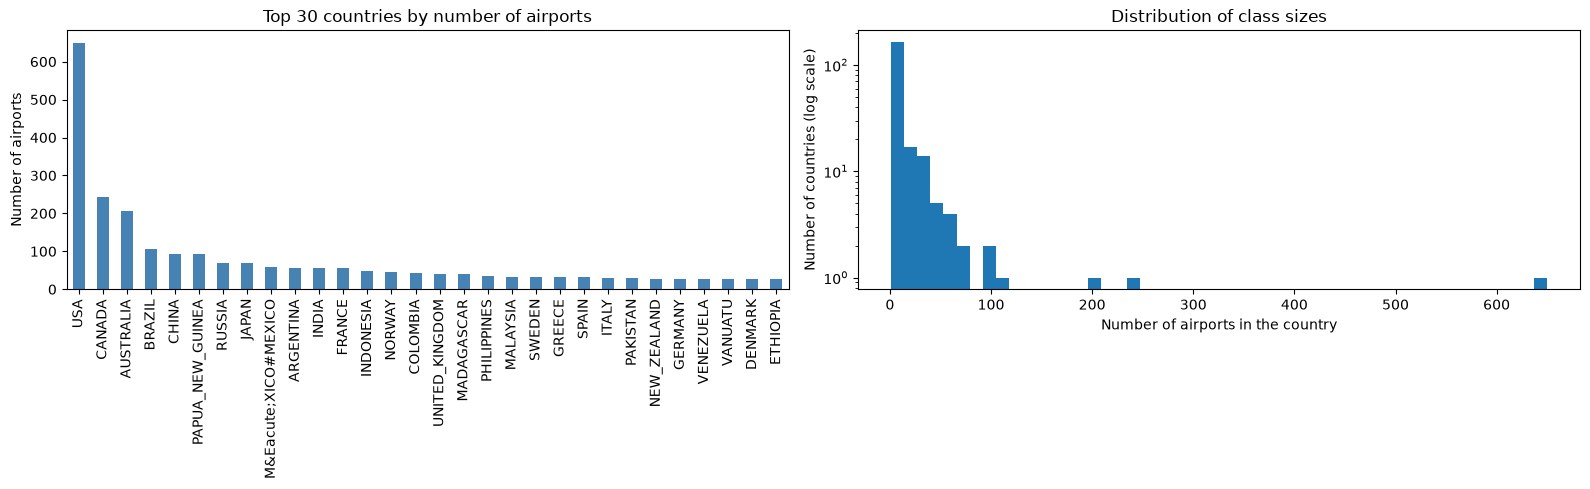

In [9]:
# Visualize the class imbalance: top 30 countries by airport count,
# plus the distribution of class sizes (log scale, since it's very skewed)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

country_counts.head(30).plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Top 30 countries by number of airports")
axes[0].set_ylabel("Number of airports")

axes[1].hist(country_counts, bins=50)
axes[1].set_yscale("log")
axes[1].set_xlabel("Number of airports in the country")
axes[1].set_ylabel("Number of countries (log scale)")
axes[1].set_title("Distribution of class sizes")

plt.tight_layout()
plt.show()

**Observation:** 212 classes for 3363 nodes, heavily imbalanced (USA alone has 650 airports, median is only 4 per country, and 62 countries have a single airport). This matters for the rest :
- A single-sample class can't appear in both train and test, so a classifier can never be correct on it - worth deciding whether to keep, merge, or drop very small classes.
- Accuracy will be dominated by big classes (USA, Canada, Australia...); a per-class metric (e.g. macro F1 or a confusion matrix) will give a fairer picture than raw accuracy.

## Data quality

Before training anything, let's check the raw attributes (`lon`, `lat`, `population`, `country`, `city_name`) for missing values and inconsistencies.

In [10]:
# Missing values and obviously invalid values

attrs_df = pd.DataFrame([d for _, d in G.nodes(data=True)])

print("Shape:", attrs_df.shape)
print("\nMissing values per column:")
print(attrs_df.isna().sum())

print("\nEmpty-string values per text column:")
for col in ["country", "city_name"]:
    print(f"  {col}: {(attrs_df[col].str.strip() == '').sum()}")

print("\npopulation <= 0:", (attrs_df["population"] <= 0).sum())
print("lon out of [-180, 180]:", ((attrs_df['lon'] < -180) | (attrs_df['lon'] > 180)).sum())
print("lat out of [-90, 90]:", ((attrs_df['lat'] < -90) | (attrs_df['lat'] > 90)).sum())
print("duplicated rows (exact):", attrs_df.duplicated().sum())

Shape: (3363, 5)

Missing values per column:
lon           0
lat           0
population    0
country       0
city_name     0
dtype: int64

Empty-string values per text column:
  country: 0
  city_name: 0

population <= 0: 0
lon out of [-180, 180]: 0
lat out of [-90, 90]: 0
duplicated rows (exact): 0


No missing/empty/out-of-range values and no exact duplicate rows. But that doesn't mean the data is clean, let's dig into the `country` labels, since `M&Eacute;XICO#MEXICO` already looked suspicious.

In [11]:
# Malformed country labels: HTML entities (e.g. "&Eacute;") and "#"-concatenated alias variants

import re

all_countries = sorted(attrs_df["country"].unique())
print("Unique country labels:", len(all_countries))

html_entity_labels = [c for c in all_countries if re.search(r"&\w+;", c)]
hash_labels = [c for c in all_countries if "#" in c]

print(f"\nLabels containing an HTML entity: {len(html_entity_labels)}")
for c in html_entity_labels:
    print(" ", c)

print(f"\nLabels containing '#' (alias concatenation): {len(hash_labels)}")
for c in hash_labels:
    print(" ", c)

Unique country labels: 212

Labels containing an HTML entity: 4
  HA&Iuml;TI#HAITI
  M&Eacute;XICO#MEXICO
  PER&Uacute;#PERU
  VI&Ecirc;T_NAM#VIET_NAM,VIETNAM

Labels containing '#' (alias concatenation): 9
  HA&Iuml;TI#HAITI
  M&Eacute;XICO#MEXICO
  PER&Uacute;#PERU
  SAINT-PIERRE_AND_MIQUELON#ST-PIERRE_AND_MIQUELON
  SAINT_HELENA#ST_HELENA
  SAINT_KITTS_AND_NEVIS#ST_KITTS_AND_NEVIS
  SAINT_LUCIA#ST_LUCIA
  SAINT_VINCENT_AND_THE_GRENADINES#ST_VINCENT_AND_THE_GRENADINES
  VI&Ecirc;T_NAM#VIET_NAM,VIETNAM


Still 212 classes after cleaning: none of the 9 malformed labels has a "clean" twin elsewhere in the dataset, so this isn't label fragmentation splitting one country into several classes, it's just unreadable strings (worth cleaning for display/readability, e.g. in plot legends, but it doesn't change the classification problem itself).

In [12]:
# Does cleaning these labels actually merge any classes together?
# (i.e. is there, e.g., a clean "MEXICO" label elsewhere that "M&Eacute;XICO#MEXICO" is a duplicate of?)

import html as html_lib

cleaned = attrs_df["country"].apply(lambda c: html_lib.unescape(c).split("#")[0])
print("Unique classes before cleaning:", attrs_df["country"].nunique())
print("Unique classes after cleaning:", cleaned.nunique())

Unique classes before cleaning: 212
Unique classes after cleaning: 212


In [22]:
from collections import Counter
import torch
import numpy as np
import networkx as nx
from torch_geometric.utils import from_networkx
from sklearn.preprocessing import StandardScaler

# ============================================================
# 1. CONFIGURATION
# ============================================================
CHEMIN_GRAPHE = "./airportsAndCoordAndPop.graphml"
SEUIL = 3

# ============================================================
# 2. TAXONOMIE ONU — MAPPING DES PAYS RARES PAR SOUS-RÉGION
# ============================================================
REGION_MAPPING = {
    # ---------------- OCÉANIE ----------------
    'WALLIS_AND_FUTUNA_ISLANDS': 'OCEANIA_POLYNESIA',
    'NIUE': 'OCEANIA_POLYNESIA',
    'TUVALU': 'OCEANIA_POLYNESIA',
    'SAMOA': 'OCEANIA_POLYNESIA',
    'AMERICAN_SAMOA': 'OCEANIA_POLYNESIA',
    'TONGA': 'OCEANIA_POLYNESIA',
    'COOK_ISLANDS': 'OCEANIA_POLYNESIA',
    'FRENCH_POLYNESIA': 'OCEANIA_POLYNESIA',
    'FIJI': 'OCEANIA_MELANESIA',
    'SOLOMON_ISLANDS': 'OCEANIA_MELANESIA',
    'VANUATU': 'OCEANIA_MELANESIA',
    'NEW_CALEDONIA': 'OCEANIA_MELANESIA',
    'PAPUA_NEW_GUINEA': 'OCEANIA_MELANESIA',
    'MARIANA_ISLANDS': 'OCEANIA_MICRONESIA',
    'GUAM': 'OCEANIA_MICRONESIA',
    'NAURU': 'OCEANIA_MICRONESIA',
    'KIRIBATI': 'OCEANIA_MICRONESIA',
    'PALAU': 'OCEANIA_MICRONESIA',
    'MARSHALL_ISLANDS': 'OCEANIA_MICRONESIA',
    'MICRONESIA': 'OCEANIA_MICRONESIA',

    # ---------------- AMÉRIQUES ----------------
    'SAINT-PIERRE_AND_MIQUELON#ST-PIERRE_AND_MIQUELON': 'AMERICAS_NORTH',
    'BERMUDA': 'AMERICAS_NORTH',
    'EL_SALVADOR': 'AMERICAS_CENTRAL',
    'NICARAGUA': 'AMERICAS_CENTRAL',
    'BELIZE': 'AMERICAS_CENTRAL',
    'CAYMAN_ISLANDS': 'AMERICAS_CARIBBEAN',
    'TRINIDAD_AND_TOBAGO': 'AMERICAS_CARIBBEAN',
    'SAINT_KITTS_AND_NEVIS#ST_KITTS_AND_NEVIS': 'AMERICAS_CARIBBEAN',
    'ANTIGUA_AND_BARBUDA': 'AMERICAS_CARIBBEAN',
    'BARBADOS': 'AMERICAS_CARIBBEAN',
    'GRENADA': 'AMERICAS_CARIBBEAN',
    'SAINT_LUCIA#ST_LUCIA': 'AMERICAS_CARIBBEAN',
    'US_VIRGIN_ISLANDS': 'AMERICAS_CARIBBEAN',
    'MARTINIQUE': 'AMERICAS_CARIBBEAN',
    'ANGUILLA': 'AMERICAS_CARIBBEAN',
    'DOMINICA': 'AMERICAS_CARIBBEAN',
    'GUYANA': 'AMERICAS_SOUTH',
    'SURINAME': 'AMERICAS_SOUTH',
    'PARAGUAY': 'AMERICAS_SOUTH',
    'URUGUAY': 'AMERICAS_SOUTH',
    'ECUADOR': 'AMERICAS_SOUTH',
    'FALKLAND_ISLANDS': 'AMERICAS_SOUTH',

    # ---------------- EUROPE ----------------
    'BELGIUM': 'EUROPE_WEST',
    'LUXEMBOURG': 'EUROPE_WEST',
    'THE_NETHERLANDS': 'EUROPE_WEST',
    'MALTA': 'EUROPE_SOUTH',
    'SLOVENIA': 'EUROPE_SOUTH',
    'ALBANIA': 'EUROPE_SOUTH',
    'MACEDONIA': 'EUROPE_SOUTH',
    'KOSOVO': 'EUROPE_SOUTH',
    'MOLDOVA': 'EUROPE_EAST',
    'BELARUS': 'EUROPE_EAST',
    'HUNGARY': 'EUROPE_EAST',
    'ESTONIA': 'EUROPE_NORTH',
    'LATVIA': 'EUROPE_NORTH',
    'LITHUANIA': 'EUROPE_NORTH',

    # ---------------- AFRIQUE ----------------
    'WESTERN_SAHARA': 'AFRICA_NORTH',
    'GUINEA_BISSAU': 'AFRICA_WEST',
    'BURKINA_FASO': 'AFRICA_WEST',
    'GHANA': 'AFRICA_WEST',
    'THE_GAMBIA': 'AFRICA_WEST',
    'LIBERIA': 'AFRICA_WEST',
    'IVORY_COAST': 'AFRICA_WEST',
    'BENIN': 'AFRICA_WEST',
    'NIGER': 'AFRICA_WEST',
    'GUINEA': 'AFRICA_WEST',
    'SIERRA_LEONE': 'AFRICA_WEST',
    'TOGO': 'AFRICA_WEST',
    'MAURITANIA': 'AFRICA_WEST',
    'CAPE_VERDE': 'AFRICA_WEST',
    'SENEGAL': 'AFRICA_WEST',
    'SAO_TOME_AND_PRINCIPE': 'AFRICA_CENTRAL',
    'EQUATORIAL_GUINEA': 'AFRICA_CENTRAL',
    'CHAD': 'AFRICA_CENTRAL',
    'CAMEROON': 'AFRICA_CENTRAL',
    'GABON': 'AFRICA_CENTRAL',
    'CONGO,_REPUBLIC_OF_THE': 'AFRICA_CENTRAL',
    'COMOROS': 'AFRICA_EAST',
    'REUNION': 'AFRICA_EAST',
    'DJIBOUTI': 'AFRICA_EAST',
    'BURUNDI': 'AFRICA_EAST',
    'RWANDA': 'AFRICA_EAST',
    'SEYCHELLES': 'AFRICA_EAST',
    'MAURITIUS': 'AFRICA_EAST',
    'ERITREA': 'AFRICA_EAST',
    'SOMALIA': 'AFRICA_EAST',
    'UGANDA': 'AFRICA_EAST',
    'MALAWI': 'AFRICA_EAST',
    'ZIMBABWE': 'AFRICA_EAST',
    'LESOTHO': 'AFRICA_SOUTH',
    'SWAZILAND': 'AFRICA_SOUTH',
    'BOTSWANA': 'AFRICA_SOUTH',
    'NAMIBIA': 'AFRICA_SOUTH',

    # ---------------- ASIE ----------------
    'JORDAN': 'ASIA_WEST',
    'BAHRAIN': 'ASIA_WEST',
    'LEBANON': 'ASIA_WEST',
    'QATAR': 'ASIA_WEST',
    'KUWAIT': 'ASIA_WEST',
    'ARMENIA': 'ASIA_WEST',
    'AZERBAIJAN': 'ASIA_WEST',
    'GEORGIA': 'ASIA_WEST',
    'CYPRUS': 'ASIA_WEST',
    'KYRGYZSTAN': 'ASIA_CENTRAL',
    'TURKMENISTAN': 'ASIA_CENTRAL',
    'TAJIKISTAN': 'ASIA_CENTRAL',
    'AFGHANISTAN': 'ASIA_CENTRAL',
    'UZBEKHISTAN': 'ASIA_CENTRAL',
    'KAZAKHSTAN': 'ASIA_CENTRAL',
    'MONGOLIA': 'ASIA_EAST',
    'NORTH_KOREA': 'ASIA_EAST',
    'SRI_LANKA': 'ASIA_SOUTH',
    'MALDIVES': 'ASIA_SOUTH',
    'BHUTAN': 'ASIA_SOUTH',
    'NEPAL': 'ASIA_SOUTH',
    'BANGLADESH': 'ASIA_SOUTH',
    'SINGAPORE': 'ASIA_SOUTHEAST',
    'BRUNEI': 'ASIA_SOUTHEAST',
    'EAST_TIMOR': 'ASIA_SOUTHEAST',
    'CAMBODIA': 'ASIA_SOUTHEAST',
    'LAOS': 'ASIA_SOUTHEAST',

    # ---------------- TERRITOIRES ISOLÉS ----------------
    'SAINT_HELENA#ST_HELENA': 'TERRITORIES_ATLANTIC',
}

# Mapping sous-région ONU → macro-région (continent)
SOUS_VERS_MACRO = {
    'OCEANIA_POLYNESIA': 'OCEANIA',
    'OCEANIA_MELANESIA': 'OCEANIA',
    'OCEANIA_MICRONESIA': 'OCEANIA',
    'AMERICAS_NORTH': 'AMERICAS',
    'AMERICAS_CENTRAL': 'AMERICAS',
    'AMERICAS_CARIBBEAN': 'AMERICAS',
    'AMERICAS_SOUTH': 'AMERICAS',
    'EUROPE_NORTH': 'EUROPE',
    'EUROPE_WEST': 'EUROPE',
    'EUROPE_SOUTH': 'EUROPE',
    'EUROPE_EAST': 'EUROPE',
    'AFRICA_NORTH': 'AFRICA',
    'AFRICA_WEST': 'AFRICA',
    'AFRICA_EAST': 'AFRICA',
    'AFRICA_CENTRAL': 'AFRICA',
    'AFRICA_SOUTH': 'AFRICA',
    'ASIA_WEST': 'ASIA',
    'ASIA_CENTRAL': 'ASIA',
    'ASIA_SOUTH': 'ASIA',
    'ASIA_EAST': 'ASIA',
    'ASIA_SOUTHEAST': 'ASIA',
    'TERRITORIES_ATLANTIC': 'OTHER',
    'UNKNOWN_REGION': 'OTHER',
}

# ============================================================
# 3. CHARGEMENT DU GRAPHE
# ============================================================
print("=" * 60)
print("CHARGEMENT DU GRAPHE")
print("=" * 60)

G = nx.read_graphml(CHEMIN_GRAPHE, node_type=int)
print(G)

nodes_list = list(G.nodes(data=True))


# ============================================================
# 4. FUSION HIÉRARCHIQUE EN 2 NIVEAUX (+ garde-fou niveau 3)
# ============================================================
print("\n" + "=" * 60)
print(f"FUSION DES PAYS < {SEUIL} NŒUDS PAR SOUS-RÉGION ONU")
print("=" * 60)

comptage_origine = Counter(d['country'] for _, d in nodes_list)


# ---- Niveau 1 : pays rare → sous-région ONU (UNKNOWN_REGION → OTHER) ----
def reetiqueter_niveau1(pays):
    if comptage_origine[pays] >= SEUIL:
        return pays
    # Les pays non listés dans REGION_MAPPING tombent directement dans OTHER
    return REGION_MAPPING.get(pays, 'OTHER')


labels_niveau1 = [reetiqueter_niveau1(d['country']) for _, d in nodes_list]
comptage_niveau1 = Counter(labels_niveau1)


# ---- Niveau 2 : sous-région trop petite → macro-région ----
def reetiqueter_niveau2(label):
    if label in comptage_origine:
        return label
    if label in SOUS_VERS_MACRO and comptage_niveau1[label] < SEUIL:
        return SOUS_VERS_MACRO[label]
    return label


labels_niveau2 = [reetiqueter_niveau2(l) for l in labels_niveau1]
comptage_niveau2 = Counter(labels_niveau2)


# ---- Niveau 3 : macro-région trop petite → OTHER (garde-fou) ----
MACRO_REGIONS = set(SOUS_VERS_MACRO.values())


def reetiqueter_niveau3(label):
    if label in comptage_origine:
        return label
    if label in MACRO_REGIONS and comptage_niveau2[label] < SEUIL:
        return 'OTHER'
    return label


labels_str = [reetiqueter_niveau3(l) for l in labels_niveau2]
comptage = Counter(labels_str)


# ---- Garde-fou final : si OTHER reste sous le seuil, on l'absorbe ----
# On le fusionne avec la plus petite macro-région existante (hors OTHER),
# afin de garantir qu'aucune classe finale ne soit sous SEUIL.
if comptage.get('OTHER', 0) < SEUIL:
    n_other = comptage.get('OTHER', 0)
    candidates = [
        c for c in comptage
        if c in MACRO_REGIONS and c != 'OTHER' and comptage[c] >= SEUIL
    ]
    if candidates:
        cible = min(candidates, key=lambda c: comptage[c])
        print(f"\n⚠️ 'OTHER' ne contient que {n_other} nœud(s) "
              f"(< {SEUIL}) → fusion dans '{cible}' ({comptage[cible]} nœuds).")
        labels_str = [cible if l == 'OTHER' else l for l in labels_str]
        comptage = Counter(labels_str)
    else:
        print(f"\n⚠️ 'OTHER' ne contient que {n_other} nœud(s) "
              f"et aucune macro-région valide n'est disponible pour l'absorber.")

classes = sorted(set(labels_str))


# ---- Vérification finale ----
n_avant = len(comptage_origine)
n_apres = len(comptage)
n_fusionnes_n1 = sum(1 for c in comptage_origine.values() if c < SEUIL)

print(f"Classes avant fusion         : {n_avant}")
print(f"Classes après fusion         : {n_apres}")
print(f"Pays fusionnés (niveau 1)    : {n_fusionnes_n1}")

petites = [(c, n) for c, n in comptage.items() if n < SEUIL]
if petites:
    print(f"\n⚠️ Classes encore < {SEUIL} :")
    for c, n in sorted(petites, key=lambda x: x[1]):
        print(f"  {c}: {n}")
else:
    print(f"\n✓ Toutes les classes ont ≥ {SEUIL} nœuds")

print("\nRépartition finale des classes :")
for pays, n in comptage.most_common():
    is_region = (
        pays in set(REGION_MAPPING.values())
        or pays in MACRO_REGIONS
        or pays == 'OTHER'
    )
    marker = "  [RÉGION]" if is_region else ""
    print(f"  {pays}: {n}{marker}")

# ============================================================
# 5. FEATURES ENRICHIES
# ============================================================
def features_enrichies(d):
    lon, lat, pop = d['lon'], d['lat'], d['population']
    return [
        lon, lat,
        np.log1p(pop),
        np.sin(np.radians(lon)), np.cos(np.radians(lon)),
        np.sin(np.radians(lat)), np.cos(np.radians(lat)),
        abs(lat) / 90.0,
        abs(lon) / 180.0,
        pop / 1e6,
    ]


x = torch.tensor(
    [features_enrichies(d) for _, d in nodes_list], dtype=torch.float
)
lat_lon_target = torch.tensor(
    [[d['lat'], d['lon']] for _, d in nodes_list], dtype=torch.float
)

pays2idx = {p: i for i, p in enumerate(classes)}
idx2pays = {i: p for p, i in pays2idx.items()}
y = torch.tensor([pays2idx[p] for p in labels_str], dtype=torch.long)

N = len(y)
K = len(classes)
print(f"\nNombre de nœuds   : {N}")
print(f"Nombre de classes : {K}")
print(f"Features          : {x.shape}")

# ============================================================
# 6. GRAPHE PyG + NORMALISATION
# ============================================================
data = from_networkx(G)
data.x = x
data.y = y
data.lat_lon = lat_lon_target

scaler_x = StandardScaler()
data.x = torch.tensor(
    scaler_x.fit_transform(data.x.numpy()), dtype=torch.float
)

scaler_ll = StandardScaler()
data.lat_lon = torch.tensor(
    scaler_ll.fit_transform(data.lat_lon.numpy()), dtype=torch.float
)

CHARGEMENT DU GRAPHE
Graph with 3363 nodes and 13547 edges

FUSION DES PAYS < 3 NŒUDS PAR SOUS-RÉGION ONU
Classes avant fusion         : 212
Classes après fusion         : 144
Pays fusionnés (niveau 1)    : 86

✓ Toutes les classes ont ≥ 3 nœuds

Répartition finale des classes :
  USA: 650
  CANADA: 243
  AUSTRALIA: 207
  BRAZIL: 105
  CHINA: 93
  PAPUA_NEW_GUINEA: 92
  RUSSIA: 70
  JAPAN: 69
  M&Eacute;XICO#MEXICO: 59
  ARGENTINA: 57
  INDIA: 57
  FRANCE: 56
  INDONESIA: 47
  NORWAY: 46
  COLOMBIA: 42
  UNITED_KINGDOM: 40
  MADAGASCAR: 40
  PHILIPPINES: 34
  MALAYSIA: 33
  SWEDEN: 33
  GREECE: 33
  SPAIN: 32
  ITALY: 31
  PAKISTAN: 31
  NEW_ZEALAND: 28
  GERMANY: 28
  VENEZUELA: 28
  VANUATU: 27
  DENMARK: 27
  ETHIOPIA: 27
  ALGERIA: 27
  SAUDI_ARABIA: 26
  TURKEY: 25
  THAILAND: 24
  IRAN: 22
  BAHAMAS: 22
  FRENCH_POLYNESIA: 21
  FINLAND: 21
  SOUTH_AFRICA: 21
  MYANMAR: 21
  MARSHALL_ISLANDS: 20
  CHILE: 17
  PER&Uacute;#PERU: 17
  FIJI: 16
  UKRAINE: 16
  SOLOMON_ISLANDS: 15
  TA

In [26]:
def class_balanced_split(labels, val_frac=0.15, test_frac=0.15, seed=0):
    """Per-class split that guarantees >=1 sample per class in val and test."""
    rng = np.random.RandomState(seed)
    labels = np.asarray(labels)
    train_idx, val_idx, test_idx = [], [], []
    for c in np.unique(labels):
        idx_c = np.where(labels == c)[0].copy()
        rng.shuffle(idx_c)
        n = len(idx_c)
        n_val = max(1, round(n * val_frac))
        n_test = max(1, round(n * test_frac))
        if n_val + n_test >= n:  # very small class: 1/1/rest
            n_val, n_test = 1, 1
        n_train = n - n_val - n_test
        train_idx.extend(idx_c[:n_train])
        val_idx.extend(idx_c[n_train:n_train + n_val])
        test_idx.extend(idx_c[n_train + n_val:])
    return np.array(train_idx), np.array(val_idx), np.array(test_idx)


# --- On récupère les labels FUSIONNÉS alignés sur l'ordre des nœuds du graphe ---
node_ids = np.array(list(G.nodes()))
# labels_str a été construit depuis nodes_list = list(G.nodes(data=True))
# donc l'ordre est identique → alignement garanti.
labels = np.array(labels_str)

train_idx, val_idx, test_idx = class_balanced_split(labels, seed=0)

n = len(labels)
print(f"train: {len(train_idx)} ({len(train_idx)/n:.1%})")
print(f"val:   {len(val_idx)} ({len(val_idx)/n:.1%})")
print(f"test:  {len(test_idx)} ({len(test_idx)/n:.1%})")
print(f"classes missing from train/val/test: "
      f"{len(set(labels) - set(labels[train_idx]))}/"
      f"{len(set(labels) - set(labels[val_idx]))}/"
      f"{len(set(labels) - set(labels[test_idx]))}")

train: 2309 (68.7%)
val:   527 (15.7%)
test:  527 (15.7%)
classes missing from train/val/test: 0/0/0


In [34]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

# --- 1. Labels ---
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(labels)   # labels = labels_str (144 classes fusionnées)

# --- 2. Features brutes : utiliser nodes_list (déjà aligné avec labels_str) ---
# nodes_list = list(G.nodes(data=True))  défini plus haut
X_raw = np.array([
    [d["lon"], d["lat"], np.log1p(d["population"])]
    for _, d in nodes_list
])

# --- 3. Normalisation fit sur train uniquement ---
scaler = StandardScaler().fit(X_raw[train_idx])
X = scaler.transform(X_raw)

print("X:", X.shape, " y:", y.shape, " classes:", len(label_encoder.classes_))
print("feature means (train):", X[train_idx].mean(axis=0))
print("feature stds (train):", X[train_idx].std(axis=0))

X: (3363, 3)  y: (3363,)  classes: 144
feature means (train): [3.31985053e-16 3.94756649e-16 1.46229210e-14]
feature stds (train): [1. 1. 1.]


In [36]:
# Condition A: features only (lon, lat, population), no graph

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score

feature_only_models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=0),
}

feature_only_results = {}
for name, clf in feature_only_models.items():
    clf.fit(X[train_idx], y[train_idx])
    pred_test = clf.predict(X[test_idx])
    macro_f1 = f1_score(y[test_idx], pred_test, average="macro")
    bal_acc = balanced_accuracy_score(y[test_idx], pred_test)
    raw_acc = (pred_test == y[test_idx]).mean()
    feature_only_results[name] = {"macro_f1": macro_f1, "balanced_acc": bal_acc, "raw_acc": raw_acc}
    print(f"{name:20s} macro-F1={macro_f1:.3f}  balanced_acc={bal_acc:.3f}  raw_acc={raw_acc:.3f}")

LogisticRegression   macro-F1=0.127  balanced_acc=0.182  raw_acc=0.351
RandomForest         macro-F1=0.487  balanced_acc=0.552  raw_acc=0.748


In [37]:
# Condition C: features + structure. Build the PyG tensors (same X, y, split as condition A)
# plus the edge_index from G_filtered, and class weights for the loss.

from sklearn.utils.class_weight import compute_class_weight

node_pos = {nid: i for i, nid in enumerate(node_ids)}
edges = np.array([[node_pos[u], node_pos[v]] for u, v in G_filtered.edges()]).T
edge_index = th.tensor(np.concatenate([edges, edges[[1, 0]]], axis=1), dtype=th.long)  # undirected

X_t = th.tensor(X, dtype=th.float)
y_t = th.tensor(y, dtype=th.long)

n_nodes = len(y)
train_mask = th.zeros(n_nodes, dtype=th.bool); train_mask[train_idx] = True
val_mask = th.zeros(n_nodes, dtype=th.bool); val_mask[val_idx] = True
test_mask = th.zeros(n_nodes, dtype=th.bool); test_mask[test_idx] = True

class_weights = th.tensor(
    compute_class_weight("balanced", classes=np.arange(len(label_encoder.classes_)), y=y[train_idx]),
    dtype=th.float,
)

print("edge_index:", edge_index.shape, " X:", X_t.shape, " y:", y_t.shape)

edge_index: torch.Size([2, 24544])  X: torch.Size([3363, 3])  y: torch.Size([3363])


In [39]:
import torch as th
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv
from sklearn.metrics import f1_score, balanced_accuracy_score


def train_gnn(model, lr=0.01, weight_decay=5e-4, max_epochs=300, patience=50, seed=0):
    th.manual_seed(seed)
    optimizer = th.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    best_val_f1, best_state, patience_ctr = -1, None, 0
    for epoch in range(max_epochs):
        model.train()
        optimizer.zero_grad()
        out = model(X_t, edge_index)
        loss = criterion(out[train_mask], y_t[train_mask])
        loss.backward()
        optimizer.step()                                     # ← '+' supprimé

        model.eval()
        with th.no_grad():
            pred = model(X_t, edge_index).argmax(dim=1)
            val_f1 = f1_score(
                y_t[val_mask].cpu().numpy(),
                pred[val_mask].cpu().numpy(),
                average="macro",
            )

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                break
    model.load_state_dict(best_state)
    return model, best_val_f1


def evaluate_gnn(model):
    model.eval()
    with th.no_grad():
        pred = model(X_t, edge_index).argmax(dim=1)
    y_true = y_t[test_mask].cpu().numpy()
    y_pred = pred[test_mask].cpu().numpy()
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    raw_acc = (pred[test_mask] == y_t[test_mask]).float().mean().item()
    return {"macro_f1": macro_f1, "balanced_acc": bal_acc, "raw_acc": raw_acc}


class GCN(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.5):
        super().__init__()
        self.conv1 = GCNConv(in_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, out_dim)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index).relu()
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)


graph_results = {}
gcn, val_f1 = train_gnn(
    GCN(in_dim=X_t.shape[1], hidden_dim=64, out_dim=len(label_encoder.classes_))
)
graph_results["GCN"] = evaluate_gnn(gcn)
print(f"GCN best val macro-F1: {val_f1:.3f}  |  test:", graph_results["GCN"])

GCN best val macro-F1: 0.277  |  test: {'macro_f1': 0.24777031558808935, 'balanced_acc': 0.3256204968546558, 'raw_acc': 0.4516128897666931}


In [40]:
# GAT: attention over neighbors instead of a fixed degree-based average

from torch_geometric.nn import GATConv


class GAT(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, heads=4, dropout=0.5):
        super().__init__()
        self.conv1 = GATConv(in_dim, hidden_dim, heads=heads, dropout=dropout)
        self.conv2 = GATConv(hidden_dim * heads, out_dim, heads=1, concat=False, dropout=dropout)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.elu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)


gat, val_f1 = train_gnn(GAT(in_dim=X_t.shape[1], hidden_dim=16, out_dim=len(label_encoder.classes_)), lr=0.005)
graph_results["GAT"] = evaluate_gnn(gat)
print(f"GAT best val macro-F1: {val_f1:.3f}  |  test:", graph_results["GAT"])

GAT best val macro-F1: 0.115  |  test: {'macro_f1': 0.11707148251169462, 'balanced_acc': 0.17563165312421267, 'raw_acc': 0.28273245692253113}


In [41]:
# SGC: GCN with the non-linearities removed between layers (K-hop linear propagation) -
# much faster, and a useful check of whether GCN's extra non-linearity is even helping here

from torch_geometric.nn import SGConv


class SGC(nn.Module):
    def __init__(self, in_dim, out_dim, K=2):
        super().__init__()
        self.conv = SGConv(in_dim, out_dim, K=K)

    def forward(self, x, edge_index):
        return self.conv(x, edge_index)


sgc, val_f1 = train_gnn(SGC(in_dim=X_t.shape[1], out_dim=len(label_encoder.classes_), K=2), lr=0.1, weight_decay=1e-5)
graph_results["SGC"] = evaluate_gnn(sgc)
print(f"SGC best val macro-F1: {val_f1:.3f}  |  test:", graph_results["SGC"])

SGC best val macro-F1: 0.218  |  test: {'macro_f1': 0.21727118556702388, 'balanced_acc': 0.27421626730142473, 'raw_acc': 0.35863378643989563}


In [42]:
# Condition A (features only) vs C (features + structure) - full comparison

all_results = pd.DataFrame({**feature_only_results, **graph_results}).T
all_results = all_results.sort_values("macro_f1", ascending=False)
all_results

,macro_f1,balanced_acc,raw_acc
RandomForest,0.487447,0.551565,0.747628
GCN,0.247770,0.325620,0.451613
SGC,0.217271,0.274216,0.358634
LogisticRegression,0.127158,0.182452,0.351044
GAT,0.117071,0.175632,0.282732


## Existant

In [25]:
country_counts_full = pd.Series([d["country"] for _, d in G.nodes(data=True)]).value_counts()
kept_countries = set(country_counts_full[country_counts_full >= MIN_CLASS_SIZE].index)

nodes_to_keep = [n for n, d in G.nodes(data=True) if d["country"] in kept_countries]
G_filtered = G.subgraph(nodes_to_keep).copy()

print(f"Classes: {country_counts_full.shape[0]} -> {len(kept_countries)} "
      f"(removed {country_counts_full.shape[0] - len(kept_countries)} classes with < {MIN_CLASS_SIZE} airports)")
print(f"Nodes: {G.number_of_nodes()} -> {G_filtered.number_of_nodes()} "
      f"(removed {G.number_of_nodes() - G_filtered.number_of_nodes()} nodes)")
print(f"Edges: {G.number_of_edges()} -> {G_filtered.number_of_edges()}")

Classes: 212 -> 126 (removed 86 classes with < 3 airports)
Nodes: 3363 -> 3253 (removed 110 nodes)
Edges: 13547 -> 12272


## filter out classes that are too small

In [23]:
MIN_CLASS_SIZE = 3

country_counts_full = pd.Series([d["country"] for _, d in G.nodes(data=True)]).value_counts()
kept_countries = set(country_counts_full[country_counts_full >= MIN_CLASS_SIZE].index)

nodes_to_keep = [n for n, d in G.nodes(data=True) if d["country"] in kept_countries]
G_filtered = G.subgraph(nodes_to_keep).copy()

print(f"Classes: {country_counts_full.shape[0]} -> {len(kept_countries)} "
      f"(removed {country_counts_full.shape[0] - len(kept_countries)} classes with < {MIN_CLASS_SIZE} airports)")
print(f"Nodes: {G.number_of_nodes()} -> {G_filtered.number_of_nodes()} "
      f"(removed {G.number_of_nodes() - G_filtered.number_of_nodes()} nodes)")
print(f"Edges: {G.number_of_edges()} -> {G_filtered.number_of_edges()}")

Classes: 212 -> 126 (removed 86 classes with < 3 airports)
Nodes: 3363 -> 3253 (removed 110 nodes)
Edges: 13547 -> 12272


##  train/val/test split

In [29]:
def class_balanced_split(labels, val_frac=0.15, test_frac=0.15, seed=0):
    """Per-class split that guarantees >=1 sample per class in val and test."""
    rng = np.random.RandomState(seed)
    labels = np.asarray(labels)
    train_idx, val_idx, test_idx = [], [], []
    for c in np.unique(labels):
        idx_c = np.where(labels == c)[0].copy()
        rng.shuffle(idx_c)
        n = len(idx_c)
        n_val = max(1, round(n * val_frac))
        n_test = max(1, round(n * test_frac))
        if n_val + n_test >= n:  # very small class: 1/1/rest
            n_val, n_test = 1, 1
        n_train = n - n_val - n_test
        train_idx.extend(idx_c[:n_train])
        val_idx.extend(idx_c[n_train:n_train + n_val])
        test_idx.extend(idx_c[n_train + n_val:])
    return np.array(train_idx), np.array(val_idx), np.array(test_idx)


node_ids = np.array(list(G_filtered.nodes()))
labels = np.array([G_filtered.nodes[n]["country"] for n in node_ids])

train_idx, val_idx, test_idx = class_balanced_split(labels, seed=0)

n = len(labels)
print(f"train: {len(train_idx)} ({len(train_idx)/n:.1%})")
print(f"val:   {len(val_idx)} ({len(val_idx)/n:.1%})")
print(f"test:  {len(test_idx)} ({len(test_idx)/n:.1%})")
print(f"classes missing from train/val/test: "
      f"{len(set(labels) - set(labels[train_idx]))}/"
      f"{len(set(labels) - set(labels[val_idx]))}/"
      f"{len(set(labels) - set(labels[test_idx]))}")

train: 2243 (69.0%)
val:   505 (15.5%)
test:  505 (15.5%)
classes missing from train/val/test: 0/0/0


In [30]:
# Features (lon, lat, log1p(population)) + label encoding.
# Scaler is fit on the train split only to avoid leakage.

from sklearn.preprocessing import LabelEncoder, StandardScaler

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(labels)

X_raw = np.array([
    [G_filtered.nodes[n]["lon"], G_filtered.nodes[n]["lat"], np.log1p(G_filtered.nodes[n]["population"])]
    for n in node_ids
])

scaler = StandardScaler().fit(X_raw[train_idx])
X = scaler.transform(X_raw)

print("X:", X.shape, " y:", y.shape, " classes:", len(label_encoder.classes_))
print("feature means (train):", X[train_idx].mean(axis=0).round(2))
print("feature stds (train):", X[train_idx].std(axis=0).round(2))

KeyError: np.int64(26)

In [35]:
# Condition A: features only (lon, lat, population), no graph

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score

feature_only_models = {
    "LogisticRegression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=0),
}

feature_only_results = {}
for name, clf in feature_only_models.items():
    clf.fit(X[train_idx], y[train_idx])
    pred_test = clf.predict(X[test_idx])
    macro_f1 = f1_score(y[test_idx], pred_test, average="macro")
    bal_acc = balanced_accuracy_score(y[test_idx], pred_test)
    raw_acc = (pred_test == y[test_idx]).mean()
    feature_only_results[name] = {"macro_f1": macro_f1, "balanced_acc": bal_acc, "raw_acc": raw_acc}
    print(f"{name:20s} macro-F1={macro_f1:.3f}  balanced_acc={bal_acc:.3f}  raw_acc={raw_acc:.3f}")

LogisticRegression   macro-F1=0.127  balanced_acc=0.182  raw_acc=0.351
RandomForest         macro-F1=0.487  balanced_acc=0.552  raw_acc=0.748


In [35]:
# Condition C: features + structure. Build the PyG tensors (same X, y, split as condition A)
# plus the edge_index from G_filtered, and class weights for the loss.

from sklearn.utils.class_weight import compute_class_weight

node_pos = {nid: i for i, nid in enumerate(node_ids)}
edges = np.array([[node_pos[u], node_pos[v]] for u, v in G_filtered.edges()]).T
edge_index = th.tensor(np.concatenate([edges, edges[[1, 0]]], axis=1), dtype=th.long)  # undirected

X_t = th.tensor(X, dtype=th.float)
y_t = th.tensor(y, dtype=th.long)

n_nodes = len(y)
train_mask = th.zeros(n_nodes, dtype=th.bool); train_mask[train_idx] = True
val_mask = th.zeros(n_nodes, dtype=th.bool); val_mask[val_idx] = True
test_mask = th.zeros(n_nodes, dtype=th.bool); test_mask[test_idx] = True

class_weights = th.tensor(
    compute_class_weight("balanced", classes=np.arange(len(label_encoder.classes_)), y=y[train_idx]),
    dtype=th.float,
)

print("edge_index:", edge_index.shape, " X:", X_t.shape, " y:", y_t.shape)

edge_index: torch.Size([2, 24544])  X: torch.Size([3253, 3])  y: torch.Size([3253])


In [ ]:
# Generic trainer (weighted CrossEntropyLoss, early stopping on val macro-F1)
# and evaluator, reused for every GNN we try below.

def train_gnn(model, lr=0.01, weight_decay=5e-4, max_epochs=300, patience=50, seed=0):
    th.manual_seed(seed)
    optimizer = th.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss(weight=class_weights)
    best_val_f1, best_state, patience_ctr = -1, None, 0
    for epoch in range(max_epochs):
        model.train()
        optimizer.zero_grad()
        out = model(X_t, edge_index)
        loss = criterion(out[train_mask], y_t[train_mask])
        loss.backward()
        optimizer.step()+

        model.eval()
        with th.no_grad():
            pred = model(X_t, edge_index).argmax(dim=1)
            val_f1 = f1_score(y_t[val_mask].numpy(), pred[val_mask].numpy(), average="macro")

        if val_f1 > best_val_f1:
            best_val_f1, best_state, patience_ctr = val_f1, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            patience_ctr += 1
            if patience_ctr >= patience:
                break
    model.load_state_dict(best_state)
    return model, best_val_f1


def evaluate_gnn(model):
    model.eval()
    with th.no_grad():
        pred = model(X_t, edge_index).argmax(dim=1)
    macro_f1 = f1_score(y_t[test_mask].numpy(), pred[test_mask].numpy(), average="macro")
    bal_acc = balanced_accuracy_score(y_t[test_mask].numpy(), pred[test_mask].numpy())
    raw_acc = (pred[test_mask] == y_t[test_mask]).float().mean().item()
    return {"macro_f1": macro_f1, "balanced_acc": bal_acc, "raw_acc": raw_acc}


class GCN(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.5):
        super().__init__()
        self.conv1 = GCNConv(in_dim, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, out_dim)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index).relu()
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)


graph_results = {}
gcn, val_f1 = train_gnn(GCN(in_dim=X_t.shape[1], hidden_dim=64, out_dim=len(label_encoder.classes_)))
graph_results["GCN"] = evaluate_gnn(gcn)
print(f"GCN best val macro-F1: {val_f1:.3f}  |  test:", graph_results["GCN"])

GCN best val macro-F1: 0.358  |  test: {'macro_f1': 0.36945305443978593, 'balanced_acc': 0.4467314660972769, 'raw_acc': 0.5267326831817627}


In [37]:
# GAT: attention over neighbors instead of a fixed degree-based average

from torch_geometric.nn import GATConv


class GAT(nn.Module):
    def __init__(self, in_dim, hidden_dim, out_dim, heads=4, dropout=0.5):
        super().__init__()
        self.conv1 = GATConv(in_dim, hidden_dim, heads=heads, dropout=dropout)
        self.conv2 = GATConv(hidden_dim * heads, out_dim, heads=1, concat=False, dropout=dropout)
        self.dropout = dropout

    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.elu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)


gat, val_f1 = train_gnn(GAT(in_dim=X_t.shape[1], hidden_dim=16, out_dim=len(label_encoder.classes_)), lr=0.005)
graph_results["GAT"] = evaluate_gnn(gat)
print(f"GAT best val macro-F1: {val_f1:.3f}  |  test:", graph_results["GAT"])

GAT best val macro-F1: 0.202  |  test: {'macro_f1': 0.16111602500982367, 'balanced_acc': 0.23585510923946298, 'raw_acc': 0.3683168292045593}


In [38]:
# SGC: GCN with the non-linearities removed between layers (K-hop linear propagation) -
# much faster, and a useful check of whether GCN's extra non-linearity is even helping here

from torch_geometric.nn import SGConv


class SGC(nn.Module):
    def __init__(self, in_dim, out_dim, K=2):
        super().__init__()
        self.conv = SGConv(in_dim, out_dim, K=K)

    def forward(self, x, edge_index):
        return self.conv(x, edge_index)


sgc, val_f1 = train_gnn(SGC(in_dim=X_t.shape[1], out_dim=len(label_encoder.classes_), K=2), lr=0.1, weight_decay=1e-5)
graph_results["SGC"] = evaluate_gnn(sgc)
print(f"SGC best val macro-F1: {val_f1:.3f}  |  test:", graph_results["SGC"])

SGC best val macro-F1: 0.252  |  test: {'macro_f1': 0.243659247435536, 'balanced_acc': 0.2936848493450973, 'raw_acc': 0.40594059228897095}


In [39]:
# Condition A (features only) vs C (features + structure) - full comparison

all_results = pd.DataFrame({**feature_only_results, **graph_results}).T
all_results = all_results.sort_values("macro_f1", ascending=False)
all_results

,macro_f1,balanced_acc,raw_acc
RandomForest,0.577881,0.626178,0.782178
GCN,0.369453,0.446731,0.526733
SGC,0.243659,0.293685,0.405941
GAT,0.161116,0.235855,0.368317
LogisticRegression,0.133413,0.195359,0.328713
